# Stage 4: Exploratory Data Analysis of the Raw Data
**Project:** Hospital Care Quality & Efficiency Analytics
**Data:** Synthea synthetic patients (seed 2026) loaded into PostgreSQL `raw` schema

**Goal:** understand the data *before* cleaning it, so the staging rules are based on evidence.

**Rule for this notebook:** SQL does the heavy lifting. Every query aggregates inside PostgreSQL and
returns a small summary table. Never `SELECT *` a big table into pandas.

| Section | Question |
|---|---|
| 1 | What tables do we have and how big are they? |
| 2 | Who are the patients? |
| 3 | What time period does the data cover? |
| 4 | What do inpatient stays look like? (length of stay, hospitals, reasons) |
| 5 | Preview of the core metrics: readmissions and mortality, and what drives the readmission patterns |
| 6 | Data quality: missing values, broken links, duplicates |
| 7 | Fan-out risk: how many diagnoses per stay? |
| 8 | Costs and payers |
| 9 | Findings and staging rules |

## 0. Setup

In [1]:
%matplotlib inline
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import text

# Find the project root (the folder containing .env) and import config.py from python/
root = Path.cwd()
while not (root / ".env").exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root / "python"))
from config import get_engine

engine = get_engine()
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)


def q(sql):
    """Run a SQL query in PostgreSQL and return the (small) result as a DataFrame."""
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn)


q("SELECT current_database() AS database, version() AS postgres_version")

,database,postgres_version
0,hospital_analytics,"PostgreSQL 18.6 on x86_64-windows, compiled by..."


**Interpretation:** The notebook is connected to the `hospital_analytics` database on PostgreSQL 18, so every query below runs inside the database and only the summary comes back to Python.

## 1. Table inventory
How many rows and columns does each raw table have? This should match the loader output exactly.

In [2]:
tables = q("""
    SELECT t.table_name,
           COUNT(c.column_name) AS columns
    FROM information_schema.tables t
    JOIN information_schema.columns c
      ON c.table_schema = t.table_schema AND c.table_name = t.table_name
    WHERE t.table_schema = 'raw'
    GROUP BY t.table_name
""")

# exact row count per table (takes a few seconds on the big tables)
tables["rows"] = [q(f"SELECT COUNT(*) AS n FROM raw.{t}")["n"][0] for t in tables["table_name"]]
tables = tables.sort_values("rows", ascending=False).reset_index(drop=True)
print(f"{len(tables)} tables, {tables['rows'].sum():,} rows in total")
tables

6 tables, 10,940,508 rows in total


,table_name,columns,rows
0,encounters,15,6680753
1,conditions,7,4142762
2,patients,28,114513
3,organizations,12,1235
4,providers,14,1235
5,payers,22,10


**Interpretation:** All 6 tables the pipeline uses are present, with 10,940,508 rows in total, matching the loader output exactly, so nothing was lost between the CSV files and the database. Two tables, `encounters` (6.7 million rows) and `conditions` (4.1 million), make up 98.9% of all rows. Synthea's other exports (claims, lab results, medications and so on) were deliberately not generated, because the core metrics do not need them.

**Columns of the core tables.** This is the starting point for the data dictionary.

In [3]:
q("""
    SELECT table_name, string_agg(column_name, ', ' ORDER BY ordinal_position) AS columns
    FROM information_schema.columns
    WHERE table_schema = 'raw'
      AND table_name IN ('patients','encounters','conditions','procedures',
                         'organizations','providers','payers')
    GROUP BY table_name
    ORDER BY table_name
""")

,table_name,columns
0,conditions,"start, stop, patient, encounter, system, code,..."
1,encounters,"id, start, stop, patient, organization, provid..."
2,organizations,"id, name, address, city, state, zip, lat, lon,..."
3,patients,"id, birthdate, deathdate, ssn, drivers, passpo..."
4,payers,"id, name, ownership, address, city, state_head..."
5,providers,"id, organization, name, gender, speciality, ad..."


**Interpretation:** The `encounters` table carries every key we need (patient, organization, provider, payer) plus start, stop and cost, so it will be the backbone of the fact table. The `patients` table includes direct identifiers (`ssn`, `drivers`, `passport`). They are synthetic, but they serve no analytical purpose and will be dropped in staging as good data-handling practice.

**What a raw row looks like** (5 inpatient encounters). Notice: everything is text, timestamps end in `Z` (UTC).

In [4]:
q("SELECT * FROM raw.encounters WHERE encounterclass = 'inpatient' LIMIT 5")

,id,start,stop,patient,organization,provider,payer,encounterclass,code,description,base_encounter_cost,total_claim_cost,payer_coverage,reasoncode,reasondescription
0,e7b42f54-0205-fcb2-7290-6dfd0087ab23,2008-04-20T13:09:08Z,2008-04-21T13:09:08Z,e7b42f54-0205-fcb2-6a4a-c267debae11e,7b20d1c4-c56b-3647-801c-5e4e13679073,424b2e94-0597-3c5e-83ab-b844f53ccf6e,a735bf55-83e9-331a-899d-a82a60b9f60c,inpatient,185347001,Encounter for problem (procedure),87.71,980.38,784.31,39898005,Sleep disorder (disorder)
1,174f5e75-14a2-22b1-f9ef-6e2172f37e58,2022-05-12T14:18:37Z,2022-05-13T14:18:37Z,174f5e75-14a2-22b1-356d-af7b7b217309,a2a41caf-758f-3962-8e5f-e6e603f93d17,2a658673-a02f-3f2d-8a99-863921b8b34e,26aab0cd-6aba-3e1b-ac5b-05c8867e762c,inpatient,305408004,Admission to surgical department (procedure),146.18,5833.06,1635.64,183996000,Sterilization requested (situation)
2,e7b42f54-0205-fcb2-8809-2e02a8f53235,2021-09-14T12:50:05Z,2021-09-15T12:50:05Z,e7b42f54-0205-fcb2-6a4a-c267debae11e,74ab949d-17ac-3309-83a0-13b4405c66aa,a5b807e0-58e7-3acd-a53d-7a3d7d137930,a735bf55-83e9-331a-899d-a82a60b9f60c,inpatient,32485007,Hospital admission (procedure),146.18,577.58,462.06,401314000,Acute non-ST segment elevation myocardial infa...
3,e7b42f54-0205-fcb2-9d15-cc747b6d3ee4,2021-09-19T03:03:24Z,2021-09-20T03:03:24Z,e7b42f54-0205-fcb2-6a4a-c267debae11e,74ab949d-17ac-3309-83a0-13b4405c66aa,a5b807e0-58e7-3acd-a53d-7a3d7d137930,a735bf55-83e9-331a-899d-a82a60b9f60c,inpatient,32485007,Hospital admission (procedure),146.18,87390.38,69912.25,274531002,Abnormal findings diagnostic imaging heart+cor...
4,e7b42f54-0205-fcb2-7c1c-21ff00e721ab,2021-09-19T11:45:39Z,2021-09-29T21:19:46Z,e7b42f54-0205-fcb2-6a4a-c267debae11e,74ab949d-17ac-3309-83a0-13b4405c66aa,a5b807e0-58e7-3acd-a53d-7a3d7d137930,a735bf55-83e9-331a-899d-a82a60b9f60c,inpatient,397821002,Patient transfer to intensive care unit (proce...,146.18,89895.20,71915.75,399261000,History of coronary artery bypass grafting (si...


**Interpretation:** Every column arrives as text, including dates and costs, so staging has to convert them to proper types. Timestamps are in ISO format with a trailing `Z` (UTC). Costs vary widely even in this small sample, from about $578 to $89,895, and payers cover between 28% and 80% of each bill. The sample also previews a pattern investigated in Section 5c: four of the five rows belong to one patient, whose September 2021 bypass surgery admission starts while an earlier cardiac imaging stay is still open.

## 2. Patients
How many patients, how many died, and what is the age and gender mix?

In [5]:
q("""
    SELECT COUNT(*)                                   AS patients,
           COUNT(deathdate)                           AS deceased,
           ROUND(100.0 * COUNT(deathdate) / COUNT(*), 1) AS pct_deceased,
           MIN(birthdate::date)                       AS oldest_birthdate,
           MAX(birthdate::date)                       AS youngest_birthdate
    FROM raw.patients
""")

,patients,deceased,pct_deceased,oldest_birthdate,youngest_birthdate
0,114513,14513,12.7,1915-11-19,2026-10-17


**Interpretation:** There are 114,513 patients, of whom 14,513 (12.7%) have died. Birth dates run from November 1915 to October 2026, so the population covers every age from newborns to centenarians. The deceased share is large enough to support a mortality metric.

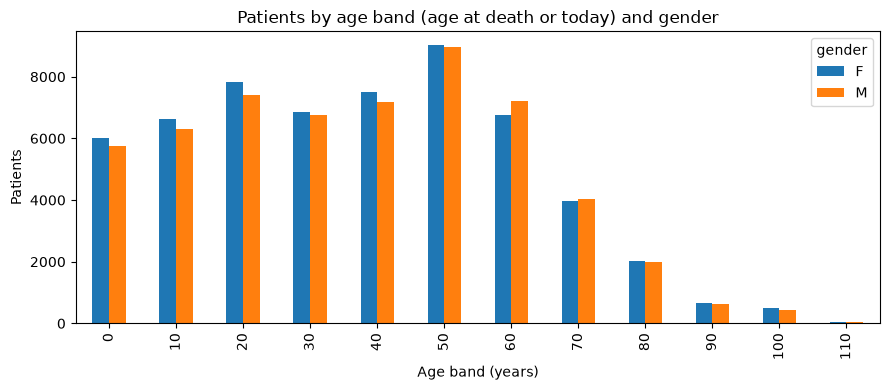

In [6]:
age = q("""
    SELECT gender,
           (FLOOR(EXTRACT(YEAR FROM age(COALESCE(deathdate::date, CURRENT_DATE),
                                        birthdate::date)) / 10) * 10)::int AS age_band,
           COUNT(*) AS patients
    FROM raw.patients
    GROUP BY 1, 2
    ORDER BY 2, 1
""")
age.pivot(index="age_band", columns="gender", values="patients").plot.bar(figsize=(9, 4))
plt.title("Patients by age band (age at death or today) and gender")
plt.xlabel("Age band (years)"); plt.ylabel("Patients"); plt.tight_layout(); plt.show()

**Interpretation:** The age mix is broad and balanced by gender. Each band from 0 to 69 holds roughly 6,000 to 9,000 patients per gender, with a peak in the 50s, and numbers fall off quickly after 70. Since older patients are admitted more often, the inpatient population will skew older than this chart.

## 3. Time coverage
Which years does the data cover? Synthea exports roughly the last 10 years of visits by default, so the
early years may look thin. **This decides the date range we use in the dashboard.**

In [7]:
q("""
    SELECT encounterclass,
           COUNT(*)                         AS visits,
           MIN(start::timestamptz)::date    AS first_visit,
           MAX(start::timestamptz)::date    AS last_visit
    FROM raw.encounters
    GROUP BY encounterclass
    ORDER BY visits DESC
""")

,encounterclass,visits,first_visit,last_visit
0,ambulatory,3671007,1916-08-21,2026-10-18
1,wellness,1401371,1916-09-24,2026-10-25
2,outpatient,862094,1917-04-29,2026-10-18
3,urgentcare,301844,1920-03-26,2026-10-18
4,emergency,251203,1916-05-24,2026-10-18
5,inpatient,107239,1917-09-02,2026-10-18
6,home,35307,1970-11-04,2026-10-18
7,virtual,17818,1999-01-31,2026-10-18
8,snf,16992,1927-05-30,2026-10-17
9,hospice,15878,1918-06-11,2026-10-18


**Interpretation:** Visits go back to 1916 for most encounter types and run up to 18 October 2026, the day the data was generated. Inpatient stays cover 1917 to 2026. A few wellness visits are dated up to a week later, which are scheduled future check-ups and fall outside any analysis window. Having a long history does not mean the history is complete, which the next chart checks.

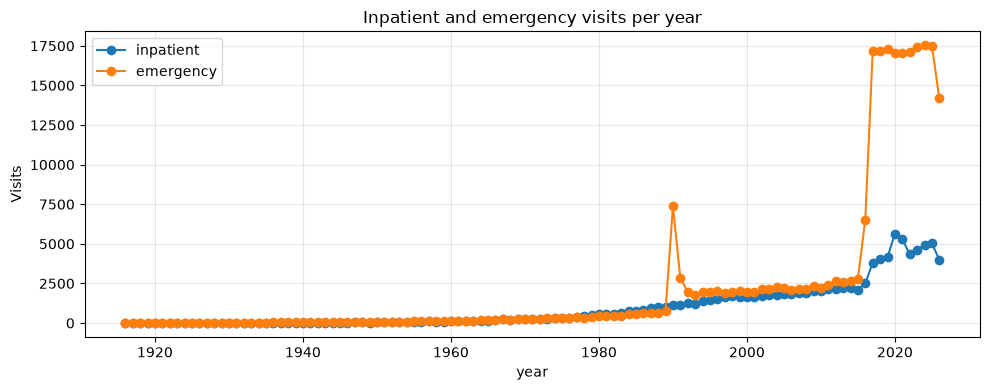

,year,inpatient,emergency
96,2012,2144,2678
97,2013,2195,2606
98,2014,2221,2635
99,2015,2110,2803
100,2016,2510,6531
101,2017,3803,17170
102,2018,4025,17159
103,2019,4161,17307
104,2020,5635,17071
105,2021,5309,17015


In [8]:
by_year = q("""
    SELECT EXTRACT(YEAR FROM start::timestamptz)::int AS year,
           COUNT(*) FILTER (WHERE encounterclass = 'inpatient') AS inpatient,
           COUNT(*) FILTER (WHERE encounterclass = 'emergency') AS emergency
    FROM raw.encounters
    GROUP BY 1
    ORDER BY 1
""")
by_year.plot(x="year", y=["inpatient", "emergency"], marker="o", figsize=(10, 4))
plt.title("Inpatient and emergency visits per year"); plt.ylabel("Visits")
plt.grid(alpha=.3); plt.tight_layout(); plt.show()
by_year.tail(15)

**Interpretation:** Volume is not stable over time. Emergency visits sit around 2,600 to 2,800 a year until 2015, ramp up through 2016 (6,531) and then hold steady at about 17,000 to 17,500 a year from 2017. Inpatient stays follow the same step, rising from about 2,100 to 2,500 a year to between 3,800 and 5,600 from 2017. Earlier decades are thin because Synthea records older history in less detail. Within the stable period, inpatient volume peaks in 2020 (5,635) and 2021 (5,309), in line with the COVID-19 admissions seen in Section 4b. The year 2026 is partial (it ends in mid-October). The reliable analysis window is therefore **2017 to 2025**, nine full years.

> **Decision:** the analysis window is **2017 to 2025**, nine full years with consistent volume. Earlier years are thinly recorded and 2026 is partial. The window is set once, in `mart.analysis_window`.

## 4. Inpatient stays
### 4a. Length of stay (LOS)
LOS in days = discharge date minus admission date. Same-day stays show 0 here; our rule will count them as 1.

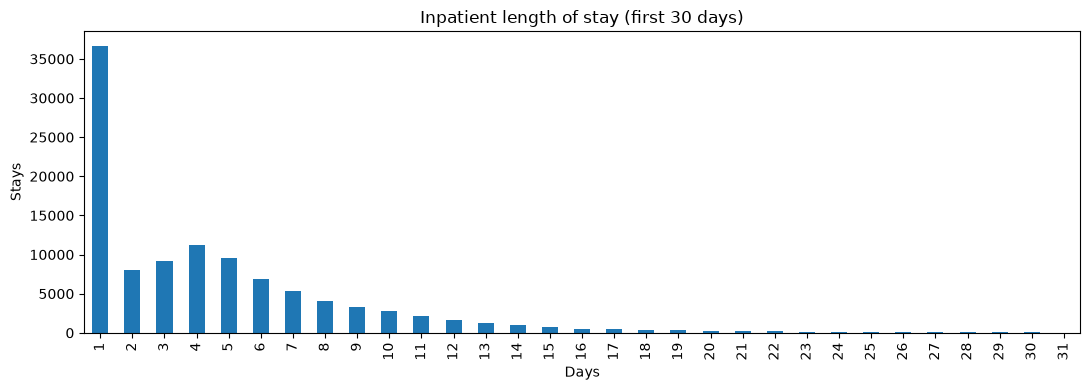

In [9]:
los = q("""
    SELECT stop::timestamptz::date - start::timestamptz::date AS los_days,
           COUNT(*) AS stays
    FROM raw.encounters
    WHERE encounterclass = 'inpatient'
    GROUP BY 1
    ORDER BY 1
""")
los.head(31).plot.bar(x="los_days", y="stays", figsize=(11, 4), legend=False)
plt.title("Inpatient length of stay (first 30 days)"); plt.xlabel("Days"); plt.ylabel("Stays")
plt.tight_layout(); plt.show()

**Interpretation:** Every stay lasts at least one calendar day; there are no same-day stays. The most common length by far is 1 day (about 37,000 stays, roughly a third of all stays), followed by a second, broader peak from 2 to 6 days (highest at 4 days) and a long tail beyond 10 days.

In [10]:
q("""
    WITH s AS (
        SELECT EXTRACT(EPOCH FROM stop::timestamptz - start::timestamptz) / 86400.0 AS los_days
        FROM raw.encounters
        WHERE encounterclass = 'inpatient'
    )
    SELECT COUNT(*)                                                         AS stays,
           ROUND(AVG(los_days)::numeric, 2)                                 AS avg_los_days,
           ROUND((PERCENTILE_CONT(0.5)  WITHIN GROUP (ORDER BY los_days))::numeric, 2) AS median,
           ROUND((PERCENTILE_CONT(0.9)  WITHIN GROUP (ORDER BY los_days))::numeric, 2) AS p90,
           ROUND(MAX(los_days)::numeric, 1)                                 AS max_days,
           COUNT(*) FILTER (WHERE los_days < 0)                             AS negative,
           COUNT(*) FILTER (WHERE los_days < 1)                             AS under_1_day,
           COUNT(*) FILTER (WHERE los_days > 30)                            AS over_30_days
    FROM s
""")

,stays,avg_los_days,median,p90,max_days,negative,under_1_day,over_30_days
0,107239,4.67,3.33,10.04,1089.0,0,0,336


**Interpretation:** The average stay is 4.67 days but the median is 3.33, which means a minority of long stays pull the average up (90% of stays end within 10 days). There are no negative or zero-length stays, so no correction is needed. However, 336 stays last longer than 30 days and the longest runs 1,089 days, about three years. These are rare but each one occupies a bed for a long time, so they are worth a closer look before the bed capacity results are finalised. On the dashboard, median length of stay should be shown alongside the average.

### 4b. Why are patients admitted? (top 15 admission reasons)

In [11]:
q("""
    SELECT COALESCE(reasondescription, '(no reason recorded)') AS admission_reason,
           COUNT(*) AS stays,
           ROUND(AVG(EXTRACT(EPOCH FROM stop::timestamptz - start::timestamptz) / 86400.0)::numeric, 1) AS avg_los_days
    FROM raw.encounters
    WHERE encounterclass = 'inpatient'
    GROUP BY 1
    ORDER BY stays DESC
    LIMIT 15
""")

,admission_reason,stays,avg_los_days
0,Non-small cell carcinoma of lung TNM stage 1 ...,28104,6.5
1,Dependent drug abuse (disorder),14059,7.5
2,Sterilization requested (situation),12255,1.0
3,History of coronary artery bypass grafting (si...,7552,2.1
4,Primary small cell malignant neoplasm of lung ...,6322,6.6
5,Sleep disorder (disorder),5221,1.0
6,Appendicitis (disorder),5209,3.0
7,Chronic congestive heart failure (disorder),5195,5.7
8,Awaiting transplantation of kidney (situation),3496,5.2
9,Abnormal findings diagnostic imaging heart+cor...,2981,1.0


**Interpretation:** Admissions are concentrated in a few conditions. Lung cancer alone accounts for 34,426 stays (32%): 28,104 non-small cell and 6,322 small cell. It is followed by drug dependence (14,059 stays, averaging 7.5 days) and elective sterilization (12,255, all one-day stays). Cardiac conditions (bypass surgery history, heart failure, heart attacks, abnormal heart imaging and valve disease) form another large group of over 21,000 stays. COVID-19 adds 2,079 stays with the longest average length in the top 15, at 9.9 days. Some of these admissions are clearly planned or elective, which matters for how readmissions are counted.

### 4c. Which hospitals have inpatient stays?

In [12]:
hosp = q("""
    SELECT o.name AS hospital, o.city,
           COUNT(*) AS stays
    FROM raw.encounters e
    LEFT JOIN raw.organizations o ON o.id = e.organization
    WHERE e.encounterclass = 'inpatient'
    GROUP BY 1, 2
    ORDER BY stays DESC
""")
print(f"{len(hosp)} hospitals have at least one inpatient stay")
print(f"Top 10 hospitals hold {hosp.head(10)['stays'].sum() / hosp['stays'].sum():.0%} of all stays")
hosp.head(15)

141 hospitals have at least one inpatient stay
Top 10 hospitals hold 35% of all stays


,hospital,city,stays
0,Fitchburg Outpatient Clinic,Fitchburg,23332
1,CAPE COD HOSPITAL INC,HYANNIS,2344
2,TEWKSBURY HOSPITAL,TEWKSBURY,2188
3,MILFORD REGIONAL MEDICAL CENTER,UPTON,1788
4,BETH ISRAEL DEACONESS HOSPITAL PLYMOUTH INC,PLYMOUTH,1529
5,AP MEDICAL LLC,DARTMOUTH,1512
6,STURDY MEMORIAL HOSPITAL INC,ATTLEBORO,1315
7,VIBRA HOSPITAL OF WESTERN MASSACHUSETTS LLC,ROCHDALE,1309
8,MELROSEWAKEFIELD HEALTHCARE INC,MELROSE,1291
9,ENCOMPASS HEALTH REHAB HOSPITAL OF WESTERN MASS,LUDLOW,1284


**Interpretation:** 141 facilities have at least one inpatient stay, and the top 10 hold 35% of them. One facility stands out: Fitchburg Outpatient Clinic has 23,332 stays (22% of all stays), about ten times the next facility. An outpatient clinic should not hold the most inpatient stays, so this is investigated below before deciding how to present hospitals.

In [ ]:
bins = pd.cut(hosp["stays"], [0, 9, 49, 99, 249, float("inf")],
              labels=["1-9", "10-49", "50-99", "100-249", "250+"])
hosp.groupby(bins, observed=False).agg(hospitals=("hospital", "count"), stays=("stays", "sum"))

**Interpretation:** Most facilities now have a meaningful volume across the full history: 112 of the 141 have 250 or more stays, and only 5 have fewer than 100. The dashboard looks at the 2017 to 2025 window rather than all years, though, where volumes per facility are much smaller, so facilities with fewer than 30 episodes in the window are still grouped into "Other" to avoid comparing rates built on a handful of cases.

**Why does one outpatient clinic hold 22% of all inpatient stays?** Look at what kind of stays it has.

In [14]:
q("""
    WITH top_facility AS (
        SELECT organization
        FROM raw.encounters
        WHERE encounterclass = 'inpatient'
        GROUP BY organization
        ORDER BY COUNT(*) DESC
        LIMIT 1
    )
    SELECT COALESCE(e.reasondescription, '(no reason recorded)') AS admission_reason,
           COUNT(*) AS stays,
           ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct_of_facility,
           ROUND(AVG(EXTRACT(EPOCH FROM e.stop::timestamptz - e.start::timestamptz) / 86400.0)::numeric, 1) AS avg_los_days
    FROM raw.encounters e
    JOIN top_facility t ON t.organization = e.organization
    WHERE e.encounterclass = 'inpatient'
    GROUP BY 1
    ORDER BY stays DESC
    LIMIT 10
""")

,admission_reason,stays,pct_of_facility,avg_los_days
0,History of coronary artery bypass grafting (si...,7552,32.4,2.1
1,Chronic congestive heart failure (disorder),5195,22.3,5.7
2,Abnormal findings diagnostic imaging heart+cor...,2981,12.8,1.0
3,Acute non-ST segment elevation myocardial infa...,2543,10.9,1.8
4,Acute ST segment elevation myocardial infarcti...,1780,7.6,1.0
5,History of aortic valve replacement (situation),1330,5.7,1.5
6,Aortic valve stenosis (disorder),989,4.2,1.0
7,Aortic valve regurgitation (disorder),456,2.0,1.0
8,Preinfarction syndrome (disorder),240,1.0,1.4
9,Non-small cell carcinoma of lung TNM stage 1 ...,132,0.6,6.4


**Interpretation:** Fitchburg's stays are almost entirely cardiac. Bypass surgery history (7,552 stays, 32%), chronic heart failure (5,195, 22%), abnormal heart imaging (2,981, 13%), heart attacks (2,543 NSTEMI and 1,780 STEMI) and aortic valve disease make up about 99% of its admissions; lung cancer accounts for most of the remaining 1%. Synthea routes cardiac care to this one facility, so it effectively acts as the network's cardiac centre. It is a real part of the data, not an error, and will be kept and labelled as the cardiac centre. Hospital comparisons will partly reflect case mix, which the dashboard should state.

> **Decision:** facilities with fewer than 30 episodes in the analysis window are grouped as "Other hospitals" on the dashboard. The threshold is kept in `mart.analysis_window`, so it is a one-line change. Fitchburg Outpatient Clinic is kept and labelled as the cardiac centre.

## 5. Preview of the core metrics
These are **rough previews**, not final numbers. The final logic (transfers, exclusions) is built in Stage 6.

### 5a. 30-day readmissions
For each inpatient stay, `LEAD()` looks at the same patient's **next** inpatient admission.

In [15]:
q("""
    WITH stays AS (
        SELECT patient,
               start::timestamptz AS admit_ts,
               stop::timestamptz  AS discharge_ts,
               LEAD(start::timestamptz) OVER (PARTITION BY patient
                                              ORDER BY start::timestamptz) AS next_admit_ts
        FROM raw.encounters
        WHERE encounterclass = 'inpatient'
    ),
    flagged AS (
        SELECT *,
               next_admit_ts::date - discharge_ts::date AS days_to_next
        FROM stays
    )
    SELECT COUNT(*)                                                     AS stays,
           COUNT(*) FILTER (WHERE days_to_next BETWEEN 0 AND 30)        AS next_admit_within_30d,
           COUNT(*) FILTER (WHERE days_to_next = 0)                     AS same_day_possible_transfer,
           COUNT(*) FILTER (WHERE days_to_next < 0)                     AS overlapping_stays,
           ROUND(100.0 * COUNT(*) FILTER (WHERE days_to_next BETWEEN 1 AND 30) / COUNT(*), 1)
                                                                        AS rough_readmit_rate_pct
    FROM flagged
""")

,stays,next_admit_within_30d,same_day_possible_transfer,overlapping_stays,rough_readmit_rate_pct
0,107239,20793,4974,1471,14.8


**Interpretation:** A rough first pass finds 20,793 stays followed by another admission within 0 to 30 days. Excluding same-day returns, the crude rate is 14.8%. But 4,974 stays have a same-day return and 1,471 overlap with the next stay, which are signs of transfers or continuous care rather than true readmissions.

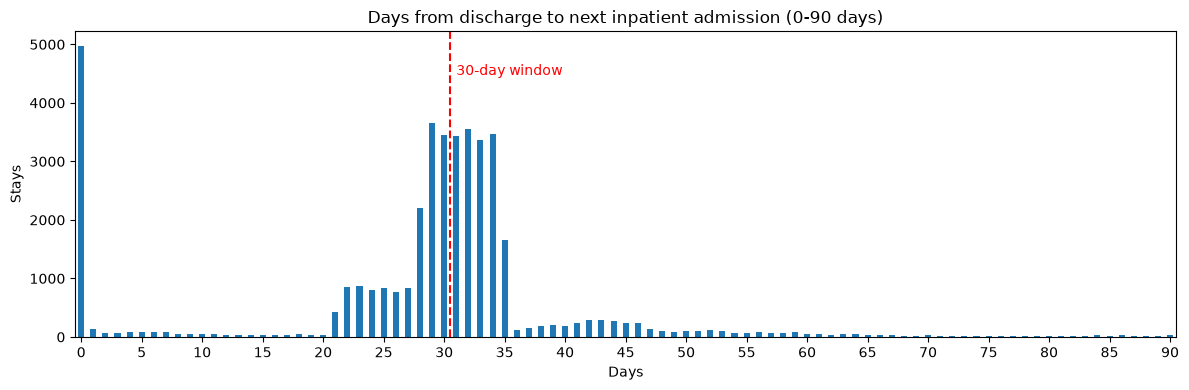

In [16]:
gap = q("""
    WITH stays AS (
        SELECT stop::timestamptz::date AS discharge_date,
               LEAD(start::timestamptz::date) OVER (PARTITION BY patient
                                                    ORDER BY start::timestamptz) AS next_admit_date
        FROM raw.encounters
        WHERE encounterclass = 'inpatient'
    )
    SELECT next_admit_date - discharge_date AS days_to_next, COUNT(*) AS stays
    FROM stays
    WHERE next_admit_date - discharge_date BETWEEN 0 AND 90
    GROUP BY 1 ORDER BY 1
""")
if gap.empty:
    print("No re-admissions within 90 days found.")
else:
    full = pd.DataFrame({"days_to_next": range(0, 91)}).merge(gap, how="left").fillna(0)
    full.plot.bar(x="days_to_next", y="stays", figsize=(12, 4), legend=False)
    plt.axvline(30.5, color="red", ls="--")
    plt.text(31, full["stays"].max() * .9, "30-day window", color="red")
    plt.xticks(range(0, 91, 5), range(0, 91, 5), rotation=0)
    plt.title("Days from discharge to next inpatient admission (0-90 days)")
    plt.xlabel("Days"); plt.ylabel("Stays"); plt.tight_layout(); plt.show()

**Interpretation:** The gap chart shows features that would distort a readmission rate. There is a spike at day 0 of about 5,000 same-day returns, and a large block of returns between days 21 and 35. That block has two steps: a shoulder at days 21 to 27 (around 800 returns a day) and a main cluster at days 28 to 35, peaking at around 3,500 a day. Such regular three- to four-week patterns look like scheduled treatment, not unplanned returns, and the 30-day cutoff slices straight through them. Section 5c investigates these features before the readmission rule is set.

> **Decision:** yes to both. Same-day and overlapping stays are merged into a single episode of care in Stage 6, so they never count as readmissions.

### 5c. Investigating the readmission patterns
The chart above has two suspicious features: a spike at **day 0** and a tight cluster at **days 28 to 35**.
Before deciding the readmission rule, we check what these stays actually are.

The base query below pairs every inpatient stay with the same patient's **next** inpatient stay and keeps
the gap in days, whether the reason is the same, and whether it is the same hospital.
Each cell reuses it as a common table expression (CTE).

In [17]:
PAIRS = """
    WITH s AS (
        SELECT id, patient, organization,
               reasondescription                      AS reason,
               start::timestamptz                     AS admit_ts,
               stop::timestamptz                      AS discharge_ts,
               LEAD(id)                    OVER w     AS next_id,
               LEAD(start::timestamptz)    OVER w     AS next_admit_ts,
               LEAD(reasondescription)     OVER w     AS next_reason,
               LEAD(organization)          OVER w     AS next_org
        FROM raw.encounters
        WHERE encounterclass = 'inpatient'
        WINDOW w AS (PARTITION BY patient ORDER BY start::timestamptz)
    ),
    pairs AS (
        SELECT *,
               next_admit_ts::date - discharge_ts::date AS gap_days,
               (next_reason = reason)                   AS same_reason,
               (next_org = organization)                AS same_hospital
        FROM s
        WHERE next_id IS NOT NULL
    )
"""

q(PAIRS + """
    SELECT CASE
             WHEN gap_days < 0              THEN '1. overlapping (< 0)'
             WHEN gap_days = 0              THEN '2. same day (0)'
             WHEN gap_days BETWEEN 1 AND 27 THEN '3. days 1-27'
             WHEN gap_days BETWEEN 28 AND 35 THEN '4. days 28-35 (cluster)'
             WHEN gap_days BETWEEN 36 AND 90 THEN '5. days 36-90'
             ELSE '6. over 90 days'
           END AS gap_bucket,
           COUNT(*) AS stay_pairs,
           ROUND(100.0 * AVG(same_reason::int), 1)   AS pct_same_reason,
           ROUND(100.0 * AVG(same_hospital::int), 1) AS pct_same_hospital
    FROM pairs
    GROUP BY 1
    ORDER BY 1
""")

,gap_bucket,stay_pairs,pct_same_reason,pct_same_hospital
0,1. overlapping (< 0),1471,2.7,99.6
1,2. same day (0),4974,88.2,99.9
2,3. days 1-27,6491,89.3,97.2
3,4. days 28-35 (cluster),24828,99.6,99.9
4,5. days 36-90,4483,89.7,96.9
5,6. over 90 days,25419,40.6,74.6


**Interpretation:** The buckets behave very differently. Of the 24,828 pairs in the 28 to 35 day cluster, 99.6% return for the same reason and 99.9% to the same hospital, which is the signature of scheduled treatment. The 4,974 same-day pairs (88.2% same reason, 99.9% same hospital) and the 1,471 overlapping pairs (99.6% same hospital) point to continuous care rather than new admissions. The overlapping pairs rarely share a reason (2.7%) because they are different steps of one pathway, explored below. Returns between days 1 and 27 also come back for the same reason 89.3% of the time, because they include the shoulder of scheduled cycles at days 21 to 27 seen in the chart. So a same-reason return is not on its own a sign of planned care, which is why the rule excludes planned treatment by diagnosis rather than by gap length.

**What brings patients back at days 28 to 35?** Top reasons for the next admission inside the cluster.

In [18]:
q(PAIRS + """
    SELECT COALESCE(next_reason, '(no reason recorded)') AS next_admission_reason,
           COUNT(*) AS readmissions,
           ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct_of_cluster,
           ROUND(100.0 * AVG(same_reason::int), 1) AS pct_same_reason_as_previous
    FROM pairs
    WHERE gap_days BETWEEN 28 AND 35
    GROUP BY 1
    ORDER BY readmissions DESC
    LIMIT 10
""")

,next_admission_reason,readmissions,pct_of_cluster,pct_same_reason_as_previous
0,Non-small cell carcinoma of lung TNM stage 1 ...,23990,96.6,99.9
1,Primary small cell malignant neoplasm of lung ...,630,2.5,99.5
2,Chronic congestive heart failure (disorder),51,0.2,78.4
3,Aortic valve stenosis (disorder),40,0.2,100.0
4,History of coronary artery bypass grafting (si...,31,0.1,80.6
5,Aortic valve regurgitation (disorder),19,0.1,94.7
6,Dependent drug abuse (disorder),15,0.1,33.3
7,Awaiting transplantation of kidney (situation),7,0.0,0.0
8,Abnormal findings diagnostic imaging heart+cor...,6,0.0,0.0
9,Acute ST segment elevation myocardial infarcti...,6,0.0,0.0


**Interpretation:** The cluster is almost entirely lung cancer: 23,990 of the readmissions (96.6%) are non-small cell lung cancer and 630 more (2.5%) are small cell lung cancer, nearly all returning for the same reason as the previous stay. These are planned treatment cycles about a month apart. Only about 200 readmissions in the cluster (under 1%) are for anything else. Counting the cancer cycles as readmissions would make the hospital look like it is failing patients when it is following a treatment plan.

**What are the same-day (day 0) re-admissions?** A transfer usually means a different hospital, or a new
admission within hours of discharge.

In [19]:
q(PAIRS + """
    SELECT COALESCE(next_reason, '(no reason recorded)') AS next_admission_reason,
           COUNT(*) AS stay_pairs,
           ROUND(100.0 * AVG(same_reason::int), 1)   AS pct_same_reason,
           ROUND(100.0 * AVG(same_hospital::int), 1) AS pct_same_hospital,
           ROUND(AVG(EXTRACT(EPOCH FROM next_admit_ts - discharge_ts) / 3600.0)::numeric, 1)
                                                     AS avg_hours_between
    FROM pairs
    WHERE gap_days = 0
    GROUP BY 1
    ORDER BY stay_pairs DESC
    LIMIT 10
""")

,next_admission_reason,stay_pairs,pct_same_reason,pct_same_hospital,avg_hours_between
0,History of coronary artery bypass grafting (si...,3897,89.7,100.0,-1.9
1,History of aortic valve replacement (situation),663,73.8,100.0,-2.1
2,Disease caused by severe acute respiratory syn...,398,100.0,100.0,-0.2
3,Non-small cell carcinoma of lung TNM stage 1 ...,5,0.0,60.0,3.0
4,History of aortic valve repair (situation),4,50.0,100.0,-3.8
5,Aortic valve regurgitation (disorder),2,50.0,50.0,3.4
6,Sleep disorder (disorder),1,0.0,100.0,-13.3
7,Aortic valve stenosis (disorder),1,100.0,100.0,3.8
8,Dependent drug abuse (disorder),1,0.0,100.0,10.8
9,Primary small cell malignant neoplasm of lung ...,1,0.0,100.0,1.3


**Interpretation:** Same-day returns are cardiac procedures and COVID-19 care at the same hospital: 3,897 bypass surgery admissions, 663 aortic valve replacements and 398 COVID-19 admissions make up 99.7% of all same-day returns, almost all at the same facility. The negative average gap (about 2 hours for the cardiac procedures) means the next admission typically starts before the previous one is closed. These are steps in one episode of care, such as a diagnostic stay followed by surgery. None of these should count as readmissions.

**What are the overlapping stays?** A new admission that starts before the previous stay has ended.

In [20]:
q(PAIRS + """
    SELECT COALESCE(reason, '(none)')      AS first_stay_reason,
           COALESCE(next_reason, '(none)') AS overlapping_stay_reason,
           COUNT(*) AS stay_pairs,
           ROUND(100.0 * AVG(same_hospital::int), 1) AS pct_same_hospital,
           ROUND(AVG(EXTRACT(EPOCH FROM discharge_ts - next_admit_ts) / 86400.0)::numeric, 1)
                                                     AS avg_overlap_days
    FROM pairs
    WHERE gap_days < 0
    GROUP BY 1, 2
    ORDER BY stay_pairs DESC
    LIMIT 10
""")

,first_stay_reason,overlapping_stay_reason,stay_pairs,pct_same_hospital,avg_overlap_days
0,Abnormal findings diagnostic imaging heart+cor...,History of coronary artery bypass grafting (si...,917,100.0,0.7
1,Aortic valve stenosis (disorder),History of aortic valve replacement (situation),380,100.0,0.9
2,Aortic valve regurgitation (disorder),History of aortic valve replacement (situation),114,100.0,0.8
3,History of coronary artery bypass grafting (si...,History of coronary artery bypass grafting (si...,31,100.0,0.0
4,History of aortic valve replacement (situation),History of aortic valve replacement (situation),4,100.0,0.0
5,Disease caused by severe acute respiratory syn...,Disease caused by severe acute respiratory syn...,3,100.0,0.0
6,Non-small cell carcinoma of lung TNM stage 1 ...,Dependent drug abuse (disorder),2,100.0,4.4
7,History of aortic valve replacement (situation),Aortic valve stenosis (disorder),2,100.0,1.0
8,Chronic congestive heart failure (disorder),Non-small cell carcinoma of lung TNM stage 1 ...,2,0.0,3.1
9,Chronic obstructive bronchitis (disorder),Dependent drug abuse (disorder),2,100.0,2.5


**Interpretation:** Overlapping stays follow the same cardiac pathway. In 917 cases an admission for abnormal heart imaging overlaps with the bypass surgery admission, and in 494 cases an aortic valve stenosis or regurgitation stay overlaps with the valve replacement. Together these make up 96% of overlaps, all at the same hospital and by less than a day on average. Staging will merge these into a single episode of care.

**How much does the readmission rate depend on the rule?** The same data under four definitions.
Denominator: all inpatient stays, excluding stays where the patient died in hospital.

In [21]:
scen = q("""
    WITH s AS (
        SELECT e.id, e.reasondescription AS reason,
               e.start::timestamptz AS admit_ts, e.stop::timestamptz AS discharge_ts,
               p.deathdate::date AS death_date,
               LEAD(e.start::timestamptz)  OVER w AS next_admit_ts,
               LEAD(e.reasondescription)   OVER w AS next_reason
        FROM raw.encounters e
        JOIN raw.patients p ON p.id = e.patient
        WHERE e.encounterclass = 'inpatient'
        WINDOW w AS (PARTITION BY e.patient ORDER BY e.start::timestamptz)
    ),
    f AS (
        SELECT *,
               next_admit_ts::date - discharge_ts::date AS gap_days,
               (death_date BETWEEN admit_ts::date AND discharge_ts::date) AS died_in_hospital
        FROM s
    ),
    eligible AS (SELECT * FROM f WHERE died_in_hospital IS NOT TRUE)
    SELECT 'A. any next stay within 0-30 days'          AS definition,
           COUNT(*) FILTER (WHERE gap_days BETWEEN 0 AND 30) AS readmissions,
           COUNT(*) AS eligible_stays
    FROM eligible
    UNION ALL
    SELECT 'B. exclude same-day and overlapping (1-30)',
           COUNT(*) FILTER (WHERE gap_days BETWEEN 1 AND 30), COUNT(*)
    FROM eligible
    UNION ALL
    SELECT 'C. B, excluding planned lung cancer treatment cycles',
           COUNT(*) FILTER (WHERE gap_days BETWEEN 1 AND 30
                              AND next_reason NOT ILIKE '%of lung%'), COUNT(*)
    FROM eligible
    UNION ALL
    SELECT 'D. B, and next stay has a different reason (strictest)',
           COUNT(*) FILTER (WHERE gap_days BETWEEN 1 AND 30
                              AND next_reason IS DISTINCT FROM reason), COUNT(*)
    FROM eligible
""")
scen["rate_pct"] = (100 * scen["readmissions"] / scen["eligible_stays"]).round(1)
scen

,definition,readmissions,eligible_stays,rate_pct
0,A. any next stay within 0-30 days,20792,106218,19.6
1,B. exclude same-day and overlapping (1-30),15819,106218,14.9
2,"C. B, excluding planned lung cancer treatment ...",1276,106218,1.2
3,"D. B, and next stay has a different reason (st...",736,106218,0.7


**Interpretation:** The definition changes the answer dramatically. Counting any return within 30 days gives 19.6%. Removing same-day and overlapping returns lowers it to 14.9%. Removing planned lung cancer cycles brings it down to **1.2% (1,276 readmissions out of 106,218 eligible stays)**. The strictest version, counting only returns for a different reason, gives 0.7%, but it would wrongly exclude cases such as a heart failure patient readmitted for heart failure, a classic unplanned readmission. Definition C is the most defensible, and it is the decision that most affects the headline metric. (These figures count raw stays across all years; once Stage 6 merges stays into episodes, the pipeline finds 1,269 unplanned readmissions overall and 639 in the 2017 to 2025 window.) Real hospitals report much higher unplanned readmission rates: Synthea models scheduled care well but generates few unexpected returns, which is a limitation to state on the dashboard.

### 5b. Mortality

In [22]:
q("""
    WITH s AS (
        SELECT e.start::timestamptz::date AS admit_date,
               e.stop::timestamptz::date  AS discharge_date,
               p.deathdate::date          AS death_date
        FROM raw.encounters e
        JOIN raw.patients p ON p.id = e.patient
        WHERE e.encounterclass = 'inpatient'
    )
    SELECT COUNT(*) AS stays,
           COUNT(*) FILTER (WHERE death_date BETWEEN admit_date AND discharge_date)        AS died_during_stay,
           COUNT(*) FILTER (WHERE death_date > discharge_date
                              AND death_date <= discharge_date + 30)                       AS died_within_30d_after,
           ROUND(100.0 * COUNT(*) FILTER (WHERE death_date BETWEEN admit_date AND discharge_date)
                 / COUNT(*), 2)                                                            AS in_hospital_mortality_pct
    FROM s
""")

,stays,died_during_stay,died_within_30d_after,in_hospital_mortality_pct
0,107239,1021,1803,0.95


**Interpretation:** 1,021 patients died during their stay (0.95% in-hospital mortality) and 1,803 more within 30 days of discharge. Spread across 141 facilities and many doctors, these deaths are still too few per facility or doctor to compare without producing unstable rates, so mortality will be reported overall and by diagnosis group only.

## 6. Data quality
### 6a. Missing values in the key encounter columns

In [23]:
q("""
    SELECT COUNT(*) AS rows,
           COUNT(*) - COUNT(id)               AS missing_id,
           COUNT(*) - COUNT(patient)          AS missing_patient,
           COUNT(*) - COUNT(start)            AS missing_start,
           COUNT(*) - COUNT(stop)             AS missing_stop,
           COUNT(*) - COUNT(organization)     AS missing_organization,
           COUNT(*) - COUNT(provider)         AS missing_provider,
           COUNT(*) - COUNT(payer)            AS missing_payer,
           COUNT(*) - COUNT(reasondescription) AS missing_reason,
           COUNT(*) - COUNT(total_claim_cost) AS missing_cost
    FROM raw.encounters
    WHERE encounterclass = 'inpatient'
""").T.rename(columns={0: "inpatient_stays"})

,inpatient_stays
rows,107239
missing_id,0
missing_patient,0
missing_start,0
missing_stop,0
missing_organization,0
missing_provider,0
missing_payer,0
missing_reason,7
missing_cost,0


**Interpretation:** The key columns are complete for all 107,239 inpatient stays. Only 7 stays are missing an admission reason, which can be labelled "Unknown" in staging.

### 6b. Duplicates and broken links (orphans)
Every count below should be **0**. Anything else becomes a staging rule.

In [24]:
q("""
    SELECT 'duplicate encounter ids' AS check_name,
           (SELECT COUNT(*) - COUNT(DISTINCT id) FROM raw.encounters) AS problems
    UNION ALL
    SELECT 'duplicate patient ids',
           (SELECT COUNT(*) - COUNT(DISTINCT id) FROM raw.patients)
    UNION ALL
    SELECT 'encounters with unknown patient',
           (SELECT COUNT(*) FROM raw.encounters e
             WHERE NOT EXISTS (SELECT 1 FROM raw.patients p WHERE p.id = e.patient))
    UNION ALL
    SELECT 'encounters with unknown organization',
           (SELECT COUNT(*) FROM raw.encounters e
             WHERE NOT EXISTS (SELECT 1 FROM raw.organizations o WHERE o.id = e.organization))
    UNION ALL
    SELECT 'encounters with unknown provider',
           (SELECT COUNT(*) FROM raw.encounters e
             WHERE NOT EXISTS (SELECT 1 FROM raw.providers pr WHERE pr.id = e.provider))
    UNION ALL
    SELECT 'encounters with unknown payer',
           (SELECT COUNT(*) FROM raw.encounters e
             WHERE NOT EXISTS (SELECT 1 FROM raw.payers py WHERE py.id = e.payer))
    UNION ALL
    SELECT 'conditions with unknown encounter',
           (SELECT COUNT(*) FROM raw.conditions c
             WHERE NOT EXISTS (SELECT 1 FROM raw.encounters e WHERE e.id = c.encounter))
    UNION ALL
    SELECT 'stays ending before they start',
           (SELECT COUNT(*) FROM raw.encounters
             WHERE stop::timestamptz < start::timestamptz)
    UNION ALL
    SELECT 'negative encounter costs',
           (SELECT COUNT(*) FROM raw.encounters WHERE total_claim_cost::numeric < 0)
""")

,check_name,problems
0,duplicate encounter ids,0
1,duplicate patient ids,0
2,encounters with unknown patient,0
3,encounters with unknown organization,0
4,encounters with unknown provider,0
5,encounters with unknown payer,0
6,conditions with unknown encounter,0
7,stays ending before they start,0
8,negative encounter costs,0


**Interpretation:** Every check returns zero: no duplicate IDs, no encounters pointing to missing patients, hospitals, doctors or payers, no stays ending before they start, and no negative costs. The raw data is structurally clean, so staging can focus on business rules rather than repairs.

## 7. Fan-out risk: diagnoses per inpatient stay
This is the biggest silent-error risk from our chokepoint list. If a stay has 3 diagnoses, joining stays to
conditions turns 1 row into 3, and every count and cost gets tripled.

In [25]:
fan = q("""
    WITH per_stay AS (
        SELECT e.id, COUNT(c.code) AS diagnoses
        FROM raw.encounters e
        LEFT JOIN raw.conditions c ON c.encounter = e.id
        WHERE e.encounterclass = 'inpatient'
        GROUP BY e.id
    )
    SELECT diagnoses, COUNT(*) AS stays
    FROM per_stay
    GROUP BY 1 ORDER BY 1
""")
total = fan["stays"].sum()
joined = (fan["diagnoses"].clip(lower=1) * fan["stays"]).sum()
print(f"{total:,} stays would become {joined:,} rows after a naive join "
      f"(x{joined / total:.2f} inflation)")
fan

107,239 stays would become 113,936 rows after a naive join (x1.06 inflation)


,diagnoses,stays
0,0,67667
1,1,37492
2,2,191
3,3,317
4,4,740
5,5,510
6,6,320
7,7,2


**Interpretation:** The fan-out risk is small (a naive join would only inflate rows by 6%, with up to 7 diagnoses on a single stay), but the more important finding is that 67,667 stays (63%) have no diagnosis at all in the `conditions` table. Synthea records a condition at the visit where it was first diagnosed, not at each admission. The `conditions` table is therefore the wrong source for why a patient was admitted; the encounter's own `reasondescription` (filled for all but 7 stays) will be used as the primary diagnosis.

> **Note:** this is why staging will pick **one primary diagnosis per stay** before joining.

## 8. Costs and payers
### 8a. Inpatient cost per stay

In [26]:
q("""
    SELECT COUNT(*)                                             AS stays,
           ROUND(AVG(total_claim_cost::numeric), 2)             AS avg_cost,
           ROUND((PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY total_claim_cost::numeric))::numeric, 2) AS median_cost,
           ROUND(MIN(total_claim_cost::numeric), 2)             AS min_cost,
           ROUND(MAX(total_claim_cost::numeric), 2)             AS max_cost,
           ROUND(SUM(total_claim_cost::numeric) / 1e6, 2)       AS total_cost_millions,
           ROUND(100 * SUM(payer_coverage::numeric) / NULLIF(SUM(total_claim_cost::numeric), 0), 1)
                                                                AS pct_covered_by_payer
    FROM raw.encounters
    WHERE encounterclass = 'inpatient'
""")

,stays,avg_cost,median_cost,min_cost,max_cost,total_cost_millions,pct_covered_by_payer
0,107239,26498.65,11106.11,87.71,690386.18,2841.69,81.6


**Interpretation:** The average stay costs $26,499 but the median is $11,106, and the most expensive stay reached $690,386. Costs are heavily right-skewed, so the median is the better headline figure. Inpatient care totals $2,841.7 million across all years, of which payers covered 81.6%.

### 8b. Who pays for inpatient stays?

In [27]:
q("""
    SELECT COALESCE(py.name, '(unknown)') AS payer,
           COUNT(*) AS stays,
           ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct_of_stays
    FROM raw.encounters e
    LEFT JOIN raw.payers py ON py.id = e.payer
    WHERE e.encounterclass = 'inpatient'
    GROUP BY 1
    ORDER BY stays DESC
""")

,payer,stays,pct_of_stays
0,Medicare,47540,44.3
1,Medicaid,13820,12.9
2,Dual Eligible,11719,10.9
3,NO_INSURANCE,10042,9.4
4,Humana,8040,7.5
5,Cigna Health,3528,3.3
6,Blue Cross Blue Shield,3458,3.2
7,Aetna,3448,3.2
8,UnitedHealthcare,2856,2.7
9,Anthem,2788,2.6


**Interpretation:** Government programs dominate: Medicare (44.3%), Medicaid (12.9%) and dual-eligible patients (10.9%) together pay for about two thirds of stays, consistent with an older inpatient population. 9.4% of stays have no insurance, which could be a useful angle when looking at costs and outcomes.

## 9. Findings and staging rules
Each finding below became a rule in the pipeline (`sql/02_staging/` and `sql/03_logic/`).

| # | What I found | Rule |
|---|---|---|
| 1 | Data coverage: inpatient stays from 1917 to 2026, with consistent volume only from 2017; 2026 is partial | Analysis window: 2017 to 2025 |
| 2 | Same-day stays: none (shortest stay is 1 day) | LOS rule: minimum 1 day (kept as a safeguard) |
| 3 | Day-0 returns: 4,974, almost all cardiac procedures or COVID-19 care at the same hospital | Merged into one episode of care, not a readmission |
| 4 | Overlapping stays: 1,471, 96% of them the cardiac pathway at the same hospital | Merged into one episode of care |
| 5 | Planned lung cancer cycles: about 24,600 returns at 28 to 35 days, plus a shoulder at 21 to 27 days | Excluded from readmissions as planned treatment |
| 6 | Hospitals with inpatient stays: 141; one cardiac centre holds 22% of stays | Group facilities under 30 episodes in the window as "Other"; label the cardiac centre |
| 7 | Diagnoses per stay: up to 7 (fan-out x1.06); 63% of stays have none in `conditions` | Use the encounter reason as the one primary diagnosis per stay |
| 8 | Missing values / orphans: 7 stays without a reason; no orphans or duplicates | Label missing reasons "Unknown" |
| 9 | Patient ID columns (ssn, drivers, passport) | Drop in staging |

**Worth a closer look with the larger data**
* **Long stays:** 336 stays last over 30 days and the longest runs 1,089 days. Check what they are before the bed capacity results are finalised.
* **COVID-19:** 2,079 stays averaging 9.9 days, with inpatient volume peaking in 2020 and 2021. This explains the busiest years in the bed occupancy results.
* **Scheduled treatment cycles:** lung cancer patients return on both three- and four-week cycles, which supports excluding planned treatment by diagnosis rather than by gap length.